# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [1]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data\zadanie-1\pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
cols = [f"{axis}{i}" for i in range(1, 9) for axis in ("x", "y")] + ["digit"]

train_df = pd.read_csv("data/zadanie-1/pendigits/pendigits.tra", header=None, names=cols)
test_df = pd.read_csv("data/zadanie-1/pendigits/pendigits.tes", header=None, names=cols)

print(f"shape: {train_df.shape}, {test_df.shape}\n")
print(train_df.describe().T)
print()
print(f'digits: {train_df["digit"].value_counts().sort_index().to_frame().T}')

shape: (7494, 17), (3498, 17)

        count       mean        std  min   25%   50%    75%    max
x1     7494.0  37.384307  33.322024  0.0   5.0  31.0   61.0  100.0
y1     7494.0  84.679343  16.848420  0.0  76.0  89.0  100.0  100.0
x2     7494.0  40.005604  26.256025  0.0  20.0  39.0   58.0  100.0
y2     7494.0  82.889512  19.638582  0.0  70.0  89.0  100.0  100.0
x3     7494.0  50.878303  34.927201  0.0  17.0  56.0   81.0  100.0
y3     7494.0  65.044436  27.377341  0.0  48.0  71.0   86.0  100.0
x4     7494.0  51.471844  30.680075  0.0  28.0  54.0   75.0  100.0
y4     7494.0  44.599680  30.659478  0.0  22.0  42.0   65.0  100.0
x5     7494.0  57.129971  33.680340  0.0  30.0  60.0   88.0  100.0
y5     7494.0  34.069122  27.459989  0.0   7.0  33.0   55.0  100.0
x6     7494.0  61.417401  37.130762  0.0  25.0  74.0   98.0  100.0
y6     7494.0  35.782092  27.495836  0.0  12.0  32.0   57.0  100.0
x7     7494.0  54.699760  22.599781  0.0  41.0  53.0   69.0  100.0
y7     7494.0  35.800774  33.22

In [5]:
missing_training_data = train_df.isna().sum().to_frame().T
print(missing_training_data)

#checking test set for safty
missing_testing_data = test_df.isna().sum().to_frame().T
print(missing_testing_data)

# checking if smth from train set leaked into test set
leaked = pd.merge(train_df, test_df)

print(f"duplicates: {train_df.duplicated().sum()}")
print(f"leaked: {len(leaked)}")

   x1  y1  x2  y2  x3  y3  x4  y4  x5  y5  x6  y6  x7  y7  x8  y8  digit
0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0      0
   x1  y1  x2  y2  x3  y3  x4  y4  x5  y5  x6  y6  x7  y7  x8  y8  digit
0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0      0
duplicates: 0
leaked: 0


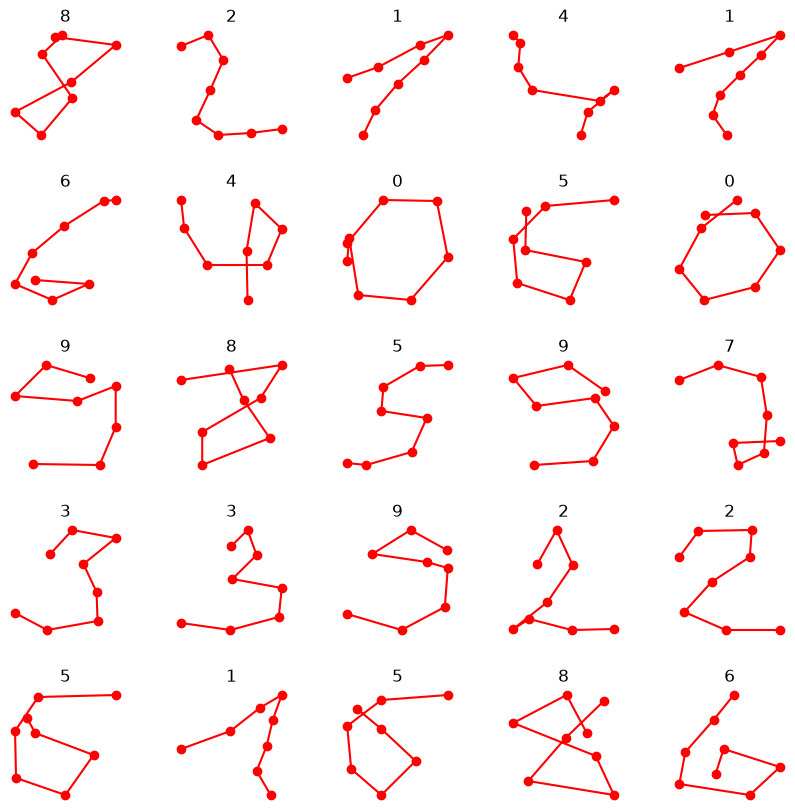

In [6]:
n = 5; m = 5;
fig, ax = plt.subplots(n, m, figsize=(10, 10))
for i in range(n * m):
    sample = train_df.iloc[i].to_numpy()
    x = sample[:16:2]
    y = sample[1:16:2]

    ax[i//m][i%m].plot(x, y, color="red", linestyle="-", marker="o")
    ax[i//m][i%m].set_title(f"{sample[16]}")
    ax[i//m][i%m].axis("off")

plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

# Wnioski:
Celem jest przewidzenie, jaką cyfrę tworzą punkty. Zbiór ma 10 klas o zbliżonej liczności, więc nie ma potrzeby stratyfikowania foldów w walidacji krzyżowej.

Analiza danych wykazała, że:
- wszystkie wartości są typu int z przedziału 0-100
- nie ma braków danych
- żaden wiersz nie występuje jednocześnie w zbiorze treningowym i testowym

Jako punkt odniesienia użyję klasyfikatora DummyClassifier (zawsze przewiduje najczęstszą klasę), który wyznacza dolną granicę jakości tzn. każdy sensowny model musi go wyraźnie przewyższać. Modelem bazowym będzie regresja logistyczna z regularyzacją L2. Ponieważ jest ona wrażliwa na skalę cech, zastosuję MinMaxScaler wewnątrz pipelina. Następnie sprawdzę random forest, który nie wymaga preprocessingu, bo jest niewrażliwy na skalę cech, a dobrze radzi sobie z zależnościami nieliniowymi. Sprawdzę również SVM z jądrem RBF, ponieważ pozwala modelować nieliniowe granice decyzyjne i może skutecznie klasyfikować dane, których nie da się dobrze rozdzielić liniowo. Spróbuję dodać cechy pochodne aby polepszyć wyniki modeli (zwłaszcza regresji logistycznej jeśli dodam nieliniowe cechy). Na końcu przetestuję hipotezę, że kolejność punktów przy pisaniu cyfry niesie dodatkową informację, wykorzystując model uwzględniające sekwencję.

In [7]:
# dropping answers from training set
X_train, y_train = train_df.drop(columns="digit"), train_df["digit"]
X_test, y_test = test_df.drop(columns="digit"), test_df["digit"]

## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [9]:
import io
import joblib

#function to calculate size of trained model
def model_size_kb(model) -> float:
    buf = io.BytesIO()
    joblib.dump(model, buf)
    return buf.getbuffer().nbytes / 1024

In [10]:
#Dummy and Logistic Regression

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "f1_macro"]
results = {}

def evaluate(name, model, count_params=None):
    res = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=True, n_jobs=-1,
    )
    model.fit(X_train, y_train)
    results[name] = {
        "cv_acc": res["test_accuracy"].mean(),
        "train_acc": res["train_accuracy"].mean(),
        "cv_f1_macro": res["test_f1_macro"].mean(),
        "fit_time_s": res["fit_time"].mean(),
        "parameters": count_params(model) if count_params else None,
        "size_kb": model_size_kb(model),
    }


#minifunctions to calculate how many parameters model has after training

def get_model_from_pipeline(p):
    return p.named_steps["clf"] if hasattr(p, "named_steps") else p

def logreg_params(p):
    clf = get_model_from_pipeline(p)
    return clf.coef_.size + clf.intercept_.size

def rf_nodes(p):
    clf = get_model_from_pipeline(p)
    return sum(t.tree_.node_count for t in clf.estimators_)

def svm_params(p):
    clf = get_model_from_pipeline(p)
    return clf.support_vectors_.size + clf.dual_coef_.size + clf.intercept_.size

In [11]:
dummy = DummyClassifier(strategy="most_frequent")
evaluate("dummy", dummy)


logreg_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("clf", LogisticRegression(penalty="l2", C=1.0, max_iter=2000))
])

evaluate("logistic_regression", logreg_pipeline, logreg_params)

pd.DataFrame(results).T.round(4)

e:\Programowanie\Python projects\Rekrutacja-AI-Med-2026-2027\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,cv_acc,train_acc,cv_f1_macro,fit_time_s,parameters,size_kb
dummy,0.0958,0.1061,0.0175,0.0211,NaN,1.0225
logistic_regression,0.9450,0.9484,0.9443,0.2604,170.0,3.6963


Dummy osiąga spodziewany wyniki tzn. około 10% "przewidując" za każdym razem najpopularniejszą klasę. Regresja logistyczna (nawet na defaultowych hiperparametrach) radzi sobie znakomicie. Wyniki na foldach walidacyjnych są zbliżone do wyników na foldach treningowych, więc model nie jest przetrenowany.

In [12]:
evaluate("random_forest", RandomForestClassifier(random_state=42), rf_nodes)

In [13]:
pd.DataFrame(results).T.round(4)

,cv_acc,train_acc,cv_f1_macro,fit_time_s,parameters,size_kb
dummy,0.0958,0.1061,0.0175,0.0211,NaN,1.0225
logistic_regression,0.9450,0.9484,0.9443,0.2604,170.0,3.6963
random_forest,0.9911,1.0000,0.9912,0.8912,60394.0,8538.4463


RandomForestClassifier poradził sobie jeszcze lepiej niż regresja logistyczna, co wskazuje na nieliniowości w danych.Niestety zajmuje znacznie więcej pamięci. Strojenie hiperparametrów może sprawić, że osiągnie podobny wynik przy niższym koszcie.

In [14]:
svm_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("clf", SVC(kernel="rbf"))
])

evaluate("svm_classifier", svm_pipeline, svm_params)

In [15]:
pd.DataFrame(results).T.round(4)

,cv_acc,train_acc,cv_f1_macro,fit_time_s,parameters,size_kb
dummy,0.0958,0.1061,0.0175,0.0211,NaN,1.0225
logistic_regression,0.9450,0.9484,0.9443,0.2604,170.0,3.6963
random_forest,0.9911,1.0000,0.9912,0.8912,60394.0,8538.4463
svm_classifier,0.9952,0.9963,0.9952,0.1636,32270.0,351.7627


SVM wysuwa się na prowadzenie mając odrobine większą dokładność niż RF a w dodatku zużywając prawie 20 razy mniej pamięci. Cena jest taka, że SVM wymaga skalowania cech, a RF nie.

Surowe dane zawierają współrzędne ośmiu punktów, ale samo ich położenie nie pokazuje jednak w pełni sposobu pisania cyfry. Ważne jest również to, w którą stronę porusza się pióro i jak zmienia kierunek.

Dlatego dodałem trzy rodzaje dodatkowych cech:

    - kierunek ruchu (różnice między współrzędnymi kolejnych punktów)
    - zakręty (sinus i cosinus kąta między kolejnymi odcinkami)
    - długość trajektorii (łączna długość drogi, jaką pokonuje pióro)

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class TrajectoryFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        points = X.reshape(len(X), -1, 2)
        vectors = np.diff(points, axis=1)
        lengths = np.linalg.norm(vectors, axis=2)

        a, b = vectors[:, :-1], vectors[:, 1:]
        cross = a[..., 0] * b[..., 1] - a[..., 1] * b[..., 0]
        dot = (a * b).sum(axis=2)
        scale = lengths[:, :-1] * lengths[:, 1:] + 1e-9
        path_len = lengths.sum(axis=1, keepdims=True)

        return np.hstack([X, vectors.reshape(len(X), -1), cross / scale, dot / scale, path_len])


def improved_pipeline(clf):
    return Pipeline([
        ("additional", TrajectoryFeatures()),
        ("scaler", MinMaxScaler()),
        ("clf", clf),
    ])

In [17]:
evaluate("logreg_improved", improved_pipeline(LogisticRegression(penalty="l2", C=1.0, max_iter=2000)), logreg_params)
evaluate("rf_improved", Pipeline([("additional", TrajectoryFeatures()), ("clf", RandomForestClassifier(random_state=42))]), rf_nodes)
evaluate("svm_improved", improved_pipeline(SVC()), svm_params)

pd.DataFrame(results).T.round(4)

e:\Programowanie\Python projects\Rekrutacja-AI-Med-2026-2027\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,cv_acc,train_acc,cv_f1_macro,fit_time_s,parameters,size_kb
dummy,0.0958,0.1061,0.0175,0.0211,NaN,1.0225
logistic_regression,0.9450,0.9484,0.9443,0.2604,170.0,3.6963
random_forest,0.9911,1.0000,0.9912,0.8912,60394.0,8538.4463
svm_classifier,0.9952,0.9963,0.9952,0.1636,32270.0,351.7627
logreg_improved,0.9856,0.9880,0.9855,0.4130,440.0,6.6025
rf_improved,0.9949,1.0000,0.9949,1.5026,47784.0,6765.0020
svm_improved,0.9949,0.9971,0.9950,0.2720,65149.0,606.7002


Największa poprawa jest dla regresji logistycznej. To dlatego, że jest to model liniowy i sam nie potrafi wykrywać takich zależności jak zakręty. Dodatkowe cechy dostarczają mu więc informacji, których wcześniej nie miał. Random Forest poprawił wynik tylko nieznacznie, ponieważ potrafi samodzielnie wykrywać zależności nieliniowe, podobnie jak SVM.

Wniosek: Kolejność punktów i sposób poruszania się pióra mają znaczenie, ale dodatkowe cechy najbardziej pomagają prostszym modelom. Bardziej zaawansowane modele potrafią część tych zależności wykryć samodzielnie. Podczas strojenia hiperparametrów modele będą mogły wybrać, czy chcą korzystać z dodatkowych cech.

## Model uwzględniający sekwencję

In [18]:
from sklearn.base import BaseEstimator, ClassifierMixin
from hmmlearn.hmm import GaussianHMM


class HMMClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, n_states=4, n_iter=50, covariance_type="diag",
                 use_deltas=False, random_state=42):
        self.n_states = n_states
        self.n_iter = n_iter
        self.covariance_type = covariance_type
        self.use_deltas = use_deltas
        self.random_state = random_state

    def _seqs(self, X):
        S = np.asarray(X, dtype=float).reshape(len(X), -1, 2)
        if self.use_deltas:
            S = np.concatenate([S, np.gradient(S, axis=1)], axis=2)
        return S

    def fit(self, X, y):
        S, y = self._seqs(X), np.asarray(y)
        T, d = S.shape[1], S.shape[2]
        K = self.n_states
        self.classes_ = np.unique(y)

        start = np.zeros(K); start[0] = 1.0
        trans = np.zeros((K, K))
        for i in range(K - 1):
            trans[i, i] = trans[i, i + 1] = 0.5
        trans[-1, -1] = 1.0
        chunks = np.array_split(np.arange(T), K)

        self.models_ = []
        for c in self.classes_:
            Sc = S[y == c]
            pts = [Sc[:, idx].reshape(-1, d) for idx in chunks]
            means = np.array([p.mean(axis=0) for p in pts])
            if self.covariance_type == "diag":
                covars = np.array([np.maximum(p.var(axis=0), 1.0) for p in pts])
            else: # "full"
                covars = np.array([np.cov(p.T) + np.eye(d) for p in pts])

            hmm = GaussianHMM(
                n_components=K, covariance_type=self.covariance_type,
                n_iter=self.n_iter, random_state=self.random_state,
                init_params="", params="stmc", transmat_prior=1.01,
            )
            hmm.startprob_, hmm.transmat_ = start.copy(), trans.copy()
            hmm.means_, hmm.covars_ = means, covars
            hmm.fit(Sc.reshape(-1, d), lengths=[T] * len(Sc))
            self.models_.append(hmm)
        return self

    def predict(self, X):
        S = self._seqs(X)
        ll = np.array([[m.score(s) for m in self.models_] for s in S])
        return self.classes_[ll.argmax(axis=1)]


def hmm_params(m):
    return sum(
        h.means_.size 
        + h.covars_.size 
        + h.transmat_.size 
        + h.startprob_.size
    for h in m.models_)

evaluate("hmm", HMMClassifier(use_deltas=True, covariance_type="full"), hmm_params)

In [19]:
pd.DataFrame(results).T.round(4)

,cv_acc,train_acc,cv_f1_macro,fit_time_s,parameters,size_kb
dummy,0.0958,0.1061,0.0175,0.0211,NaN,1.0225
logistic_regression,0.9450,0.9484,0.9443,0.2604,170.0,3.6963
random_forest,0.9911,1.0000,0.9912,0.8912,60394.0,8538.4463
svm_classifier,0.9952,0.9963,0.9952,0.1636,32270.0,351.7627
logreg_improved,0.9856,0.9880,0.9855,0.4130,440.0,6.6025
rf_improved,0.9949,1.0000,0.9949,1.5026,47784.0,6765.0020
svm_improved,0.9949,0.9971,0.9950,0.2720,65149.0,606.7002
hmm,0.9529,0.9545,0.9527,153.4883,1000.0,16.4092


Każda obserwacja zawiera położenie punktu i kierunek ruchu (x, y, dx, dy). Samo położenie punktów może nieco się różnic między tymi samymi cyframi, natomiast kierunek ruchu jest bardziej charakterystyczny dla danej cyfry. Dlatego zdecydowałem się uwzględnić delty. Wybrałem również pełną macierz kowariancji, ponieważ położenie i kierunek ruchu mogą być ze sobą powiązane.

HMM osiągnął wynik 0,953 trochę gorszy od pozostałych modeli (0,987–0,995). Możliwym wyjaśnieniem jest to, że HMM uczy się osobno, jak wygląda każda cyfra, zamiast bezpośrednio szukać różnic między klasami. Może to utrudniać rozpoznawanie podobnych cyfr, np. 1 i 7. Dodatkowo tylko 4 stany dla 8 punktów dają dość uproszczony opis trajektorii, a założenie niezależności obserwacji w obrębie stanu może powodować utratę części informacji. Dodatkowo trening HMM trwa około dwóch minut, podczas gdy pozostałe modele uczą się w mniej niż dwie sekundy. Predykcja również jest wolniejsza, ponieważ wymaga przejścia przez 10 osobnych modeli. Biorąc pod uwagę znacznie gorszy wynik i wysoki koszt obliczeniowy, HMM nie jest opłacalnym wyborem i nie będzie używany w dalszej części notebooka.


## Hiperparametry

Hiperparametry dobrano za pomocą Optuny (sampler TPE, seed=42) z pięciokrotną walidacją krzyżową. Cechy pochodne były jednym z hiperparametrów.

In [20]:
import optuna
from sklearn.model_selection import cross_val_score
import time

optuna.logging.set_verbosity(optuna.logging.WARNING)

def build_model(name, trial):
    use_motion = trial.suggest_categorical("additional_features", [False, True])

    if name == "logreg":
        clf = LogisticRegression(C=trial.suggest_float("C", 1e-2, 1e3, log=True), max_iter=2000)
    elif name == "rf":
        clf = RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 400),
            max_depth=trial.suggest_int("max_depth", 8, 40),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 5),
            max_features=trial.suggest_float("max_features", 0.2, 1.0),
            random_state=42,
        )
    else:  # svm
        clf = SVC(
            C=trial.suggest_float("C", 0.1, 1e3, log=True),
            gamma=trial.suggest_float("gamma", 1e-3, 10, log=True),
        )

    return Pipeline([
        ("feat", TrajectoryFeatures() if use_motion else "passthrough"),
        ("scaler", MinMaxScaler()),
        ("clf", clf),
    ])

n_trials = {"logreg": 30, "rf": 30, "svm": 30}
tuned, tuned_fit_time = {}, {}

for name in ["logreg", "rf", "svm"]:
    def objective(trial):
        scores = cross_val_score(build_model(name, trial), X_train, y_train,
                                 cv=cv, scoring="accuracy", n_jobs=-1)
        return scores.mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=n_trials[name])

    best = build_model(name, optuna.trial.FixedTrial(study.best_params))
    start = time.perf_counter()
    best.fit(X_train, y_train)
    tuned_fit_time[name] = time.perf_counter() - start
    tuned[name] = best

    print(f"{name}: cv_acc = {study.best_value:.4f}")
    print("--]", study.best_params)

logreg: cv_acc = 0.9899
--] {'additional_features': True, 'C': 10.129197956845726}
rf: cv_acc = 0.9949
--] {'additional_features': True, 'n_estimators': 300, 'max_depth': 17, 'min_samples_leaf': 2, 'max_features': 0.20386952213625825}
svm: cv_acc = 0.9972
--] {'additional_features': True, 'C': 22.24933372487188, 'gamma': 0.1615442366045914}


## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

In [21]:
import time
from sklearn.metrics import accuracy_score, f1_score

def timed_fit(model):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    return model, time.perf_counter() - start

final_models = {
    "logreg": (tuned["logreg"], tuned_fit_time["logreg"], logreg_params),
    "rf": (tuned["rf"], tuned_fit_time["rf"], rf_nodes),
    "svm": (tuned["svm"], tuned_fit_time["svm"], svm_params),
}

rows, predictions = {}, {}
for name, (model, fit_time, count_params) in final_models.items():
    start = time.perf_counter()
    pred = model.predict(X_test)
    predict_time = time.perf_counter() - start

    predictions[name] = pred
    rows[name] = {
        "test_acc": accuracy_score(y_test, pred),
        "test_f1_macro": f1_score(y_test, pred, average="macro"),
        "fit_time_s": fit_time,
        "predict_time_s": predict_time,
        "parameters": count_params(model) if count_params else None,
        "size_kb": model_size_kb(model),
    }

test_table = pd.DataFrame(rows).T.round(4)

In [22]:
test_table

,test_acc,test_f1_macro,fit_time_s,predict_time_s,parameters,size_kb
logreg,0.9694,0.9695,0.2891,0.0034,440.0,6.6182
rf,0.9734,0.9739,6.5416,0.1169,112752.0,15995.4238
svm,0.9831,0.9833,0.2940,0.2666,41437.0,387.5596


Best model: svm (0.9831)


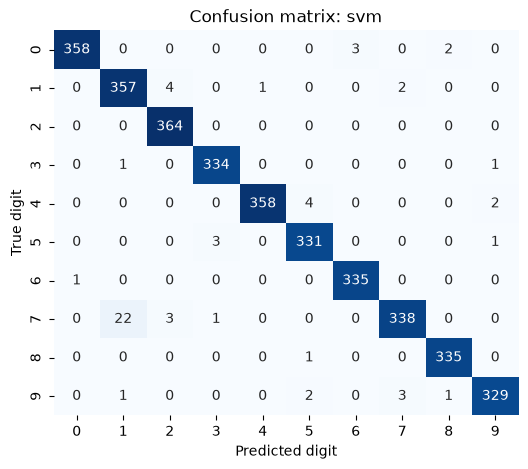

              precision    recall  f1-score   support

           0     0.9972    0.9862    0.9917       363
           1     0.9370    0.9808    0.9584       364
           2     0.9811    1.0000    0.9905       364
           3     0.9882    0.9940    0.9911       336
           4     0.9972    0.9835    0.9903       364
           5     0.9793    0.9881    0.9837       335
           6     0.9911    0.9970    0.9941       336
           7     0.9854    0.9286    0.9562       364
           8     0.9911    0.9970    0.9941       336
           9     0.9880    0.9792    0.9836       336

    accuracy                         0.9831      3498
   macro avg     0.9836    0.9834    0.9833      3498
weighted avg     0.9834    0.9831    0.9831      3498



In [23]:
# Find the best model

ranking = test_table.sort_values("test_acc", ascending=False)
winner = ranking.index[0]

print(f"Best model: {winner} ({ranking.loc[winner, 'test_acc']:.4f})")

# Confusion matrix
cm = confusion_matrix(y_test, predictions[winner])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.title(f"Confusion matrix: {winner}")
plt.show()

print(classification_report(y_test, predictions[winner], digits=4))

Most common misclassifications:
7 predicted as 1: 22 times
4 predicted as 5: 4 times
1 predicted as 2: 4 times


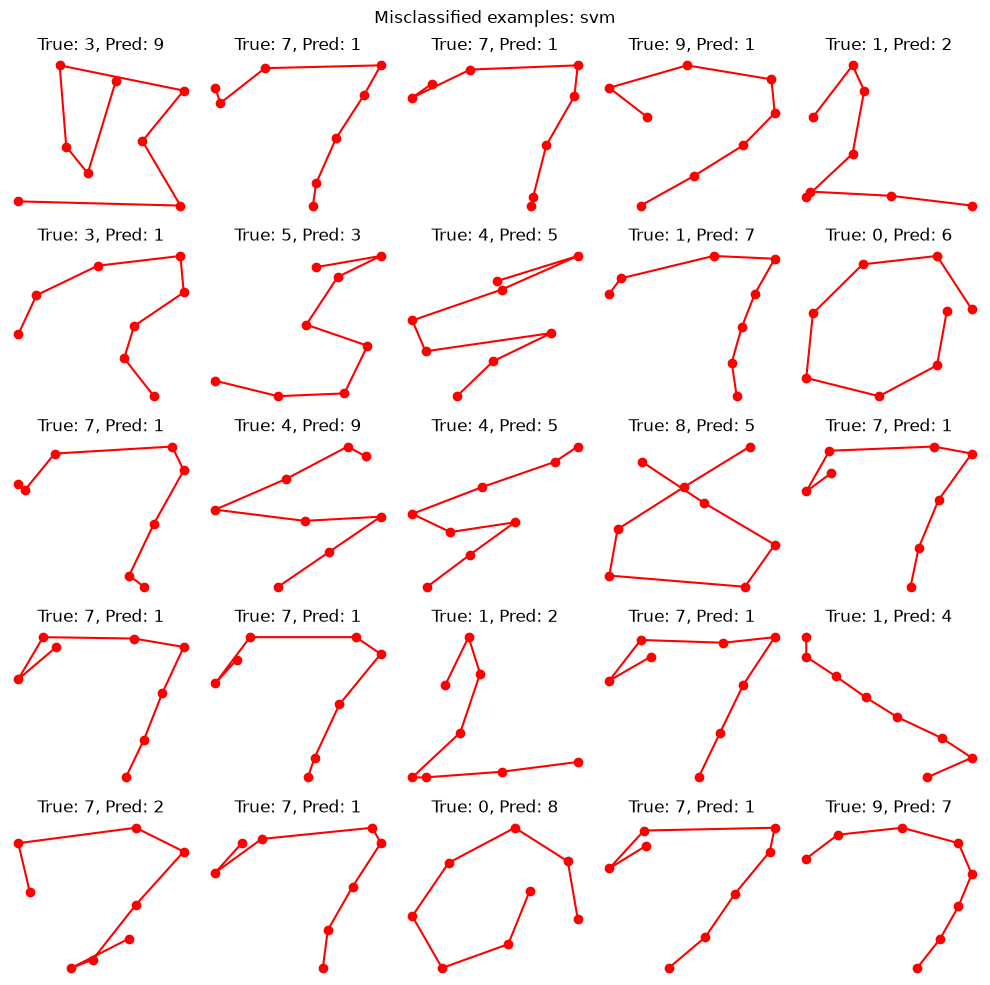

In [24]:
errors = [
    (cm[i, j], i, j)
    for i in range(10)
    for j in range(10)
    if i != j
]

print("Most common misclassifications:")
for count, true, predicted in sorted(errors, reverse=True)[:3]:
    print(f"{true} predicted as {predicted}: {count} times")

y_pred = predictions[winner]
error_indices = np.where(y_pred != y_test.to_numpy())[0]

n, m = 5, 5
fig, ax = plt.subplots(n, m, figsize=(10, 10))

for i, idx in enumerate(error_indices[:n * m]):
    sample = test_df.iloc[idx].to_numpy()
    x = sample[:16:2]
    y = sample[1:16:2]

    ax[i // m, i % m].plot(x, y, color="red", marker="o")
    ax[i // m, i % m].set_title(
        f"True: {y_test.iloc[idx]}, Pred: {y_pred[idx]}"
    )
    ax[i // m, i % m].axis("off")

for i in range(len(error_indices), n * m):
    ax[i // m, i % m].axis("off")

plt.suptitle(f"Misclassified examples: {winner}")
plt.tight_layout()
plt.show()

## Podsumowanie

Najlepszy wynik uzyskał model SVM, osiągając accuracy 98,31% i macro F1 98,33%. Na drugim miejscu jest Random Forest, a ostatnia regresja logistyczna. SVM okazał się najlepszy zarówno pod względem skuteczności jak i kosztu obliczeniowego. Zajmuje około 388 KB i trenuje się w 0,2 s, podczas gdy Random Forest zajmuje prawie 16 MB i wymaga 6,6 s treningu. Analiza macierzy pomyłek wskazuje, że największą trudność sprawia rozróżnianie cyfr 7 i 1, które zostały pomylone aż 22 razy. Wynika to z podobieństwa ich kształtów oraz ograniczonej liczby punktów opisujących każdą cyfrę. Pozostałe klasy są rozpoznawane z bardzo wysoką skutecznością. Eksperyment z cechami pochodnymi pokazał, że uwzględnienie kierunku ruchu, zakrętów i długości trajektorii znacząco poprawia wyniki regresji logistycznej. W przypadku SVM poprawa była niewielka, ponieważ model sam potrafi wykrywać bardziej złożone zależności. Pokazuje to, że informacja o kolejności punktów może być pomocna, ale nie zawsze jest kluczowa, szczególnie gdy model potrafi samodzielnie uchwycić strukturę danych. Podobny wniosek wynika z eksperymentu z modelem HMM, który wykorzystywał położenie punktów oraz kierunek ruchu, opisywany przez delty (dx, dy). Zastosowanie pełnej macierzy kowariancji miało uwzględnić zależności między położeniem a kierunkiem ruchu. Mimo tego HMM osiągnął dokładność 95,3%, czyli wynik trochę gorszy od pozostałych modeli. Jednym z powodów może być uproszczony opis trajektorii za pomocą czterech stanów oraz sposób uczenia osobnego modelu dla każdej cyfry. Dodatkowo trening trwał około dwóch minut, a predykcja była wolniejsza ze względu na konieczność wykorzystania dziesięciu modeli. W związku z tym HMM nie okazał się opłacalnym rozwiązaniem i został odrzucony. Eksperymenty pokazały, że uwzględnianie kolejności punktów i stosowanie bardziej złożonych modeli sekwencyjnych nie zawsze przynosi korzyści.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.

Żródła:
- Aurelien Geron "Uczenie maszynowe z użyciem Scikit-Learn i TensorFlow"
- https://en.wikipedia.org/wiki/Hidden_Markov_model
- https://claude.ai